# Stage 10 — Monitoring and drift detection

**Problem:** after deployment nobody gives you labels. A model that scored well on the test set can quietly get
worse (camera moved, lighting changed, new batch). We watch *proxies*: do the inputs and the model's scores still
look like they did when the model was set up?

**This notebook uses SIMULATED data** (normal-distributed brightness values) to explain the statistics. It is not
a result about the real camera. In the real app the reference comes from your normal validation images
(`models/monitoring_reference.json`) and production values come from `logs/predictions.jsonl`.

In [ ]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT / "src"))
import monitoring as mon

rng = np.random.default_rng(0)
reference = rng.normal(120, 10, 200)            # SIMULATED brightness of 200 normal reference images

## 1. What drift looks like
Production brightness drawn from the same distribution, then from a distribution shifted by +1 standard deviation (+10 grey levels).

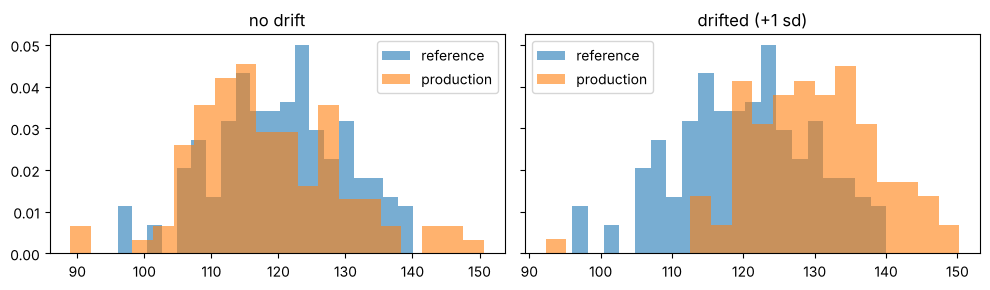

In [ ]:
same    = rng.normal(120, 10, 100)
shifted = rng.normal(130, 10, 100)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, cur, title in zip(axes, (same, shifted), ("no drift", "drifted (+1 sd)")):
    ax.hist(reference, bins=20, alpha=.6, density=True, label="reference")
    ax.hist(cur, bins=20, alpha=.6, density=True, label="production")
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

## 2. PSI — how far did the distribution move?
Bin the reference into quantile bins, compare the share of production samples in each bin:
`PSI = sum((cur% - ref%) * ln(cur% / ref%))`. Rule of thumb: < 0.1 stable, 0.1-0.25 moderate, > 0.25 major.

In [ ]:
for name, cur in (("same", same), ("shifted +1sd", shifted)):
    print(f"{name:14s} PSI = {mon.psi(reference, cur):.3f}")

same           PSI = 0.086
shifted +1sd   PSI = 1.056


## 3. KS test — is the shift bigger than chance?
The Kolmogorov-Smirnov test compares the two empirical distributions; a small p-value means they probably differ.

In [ ]:
for name, cur in (("same", same), ("shifted +1sd", shifted)):
    r = stats.ks_2samp(reference, cur)
    print(f"{name:14s} KS statistic = {r.statistic:.3f}, p = {r.pvalue:.4g}")

same           KS statistic = 0.170, p = 0.04063
shifted +1sd   KS statistic = 0.395, p = 1.005e-09


## 4. Why `monitoring.py` combines them (and does not trust either alone)
PSI is biased upward on small samples; testing three signals at once inflates false alarms. So a signal is flagged
only when PSI *and* KS agree, KS limits are divided by the number of tests (Bonferroni), and PSI bins adapt to the
sample size. The simulation below measures the result: how often is "no drift" data flagged (false alarm), and how
often is a real shift caught?

In [ ]:
def flagged_rate(n, shift, trials=300):
    hits = 0
    for t in range(trials):
        r = np.random.default_rng(t)
        ref = mon.build_reference(r.normal(.5,.1,200), r.normal(120,10,200), r.normal(40,5,200), "v1", "sim")
        df = pd.DataFrame({"score": r.normal(.5,.1,n), "brightness": r.normal(120+shift,10,n),
                           "contrast": r.normal(40,5,n), "model_version": "v1"})
        hits += mon.drift_report(ref, df, "v1")["status"] != "ok"
    return hits / trials

rows = [{"samples": n, "no shift (false alarm)": flagged_rate(n, 0), "shift +0.5 sd": flagged_rate(n, 5),
         "shift +1 sd": flagged_rate(n, 10), "shift +2 sd": flagged_rate(n, 20)} for n in (30, 100, 500)]
pd.DataFrame(rows).set_index("samples").round(3)

,no shift (false alarm),shift +0.5 sd,shift +1 sd,shift +2 sd
samples,,,,
30,0.050,0.450,0.977,1.0
100,0.047,0.853,1.000,1.0
500,0.043,1.000,1.000,1.0


## 5. Reading the real log
After using the app or API, `logs/predictions.jsonl` holds one line per prediction.

In [ ]:
log = mon.read_log(PROJECT_ROOT / "logs" / "predictions.jsonl")
if log.empty:
    print("No predictions logged yet. Upload images in the Streamlit app or call the API, then re-run this cell.")
else:
    print(mon.summarize(log))
    ref = mon.load_reference(PROJECT_ROOT / "models" / "monitoring_reference.json")
    version = mon.compute_model_version(PROJECT_ROOT / "models" / "resnet_ocsvm_bundle.joblib")
    print(mon.drift_report(ref, log, version))

## What this cannot tell you
Without ground-truth labels, drift means *the data or scores changed*, not *accuracy dropped*. A real deployment would
send a random sample of bottles to a human inspector to measure true accuracy over time.